# Výhody a nevýhody metody Slice Sampling v bayesovské inverzi

V bayesovské inverzi se ke generování vzorků z výsledného rozdělení pravděpodobnosti nejčastěji používají metody založené na algoritmu **Random Walk Metropolis** (RWM) – nejjednodušší variantě obecnějšího algoritmu Metropolis-Hastings. Tato práce bude zkoumat **slice sampling** jako alternativu, která může být v některých situacích robustnější a snáze nastavitelná.

## Předběžná osnova práce

**Teoretická část:**
1. Bayesovská inverze (stačí stručně — jako motivace proč vzorkovat)
2. Metoda Random Walk Metropolis (stačí stručně — bude použita pro porovnání)
3. Metoda Slice Sampling (detailně — princip, varianty, vlastnosti)

**Praktická část:**
1. Implementace obou metod — RWM a slice sampling včetně vícerozměrných variant (po souřadnicích, hyperobdélník, náhodné směry, příp. elliptical slice sampling)
2. Soubor testovacích úloh (různé tvary rozdělení, různé dimenze) a alespoň jedna skutečná úloha bayesovské inverze (model + zašuměná data → aposteriorní rozdělení)
3. Srovnání na testovacích úlohách — robustnost vůči volbě parametrů, efektivita měřená jako ESS na jedno vyhodnocení hustoty, náročnost ladění
4. Zhodnocení — kdy se vyplatí použít slice sampling místo RWM

In [1]:
import importlib, samplers
importlib.reload(samplers)

import numpy as np
import time
import matplotlib.pyplot as plt
from samplers import slice_sampling, slice_sampling_one_step, metropolis_hastings

## Ukázka vzorkování z 1d rozdělení pravděpodobnosti

Jako cílové rozdělení použijeme směs dvou normálních rozdělení s následující hustotou pravděpodobnosti:

$$p(x) = 0{,}3 \cdot \mathcal{N}(x;\,-2,\,1^2) \;+\; 0{,}7 \cdot \mathcal{N}(x;\,2,\,0{,}7^2),$$

kde $\mathcal{N}(x;\,\mu,\,\sigma^2)$ značí hustotu normálního rozdělení se střední hodnotou $\mu$ a směrodatnou odchylkou $\sigma$ (tj. rozptylem $\sigma^2$).

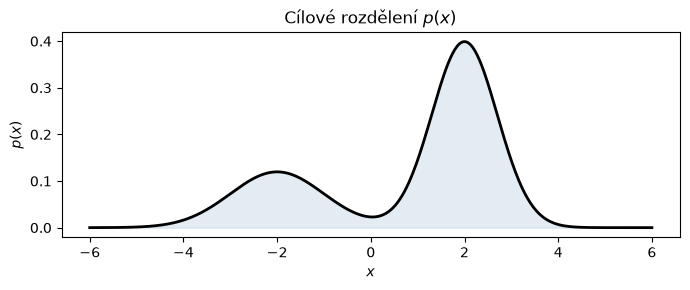

In [2]:
# --- Cílové rozdělení ---
def normal_pdf(x, mu, sigma):
    return np.exp(-0.5 * ((x - mu) / sigma) ** 2) / (sigma * np.sqrt(2 * np.pi))

def target_pdf(x):
    return 0.3 * normal_pdf(x, -2, 1.0) + 0.7 * normal_pdf(x, 2, 0.7)

def log_target_pdf(x):
    p = target_pdf(x)
    return np.log(p) if p > 0 else -np.inf

# Vizualizace
x_grid = np.linspace(-6, 6, 500)
plt.figure(figsize=(7, 3))
plt.plot(x_grid, target_pdf(x_grid), 'k-', lw=2)
plt.fill_between(x_grid, target_pdf(x_grid), alpha=0.15, color='steelblue')
plt.title("Cílové rozdělení $p(x)$")
plt.xlabel("$x$"); plt.ylabel("$p(x)$")
plt.tight_layout(); plt.show()

## Random Walk Metropolis (běžně používaná metoda)

RWM v každém kroku:
1. Navrhne $x' = x + \varepsilon$, kde $\varepsilon \sim \mathcal{N}(0, \sigma^2)$.
2. Spočte pravděpodobnost přijetí $\alpha = \min\!\big(1,\; p(x')/p(x)\big)$.
3. S pravděpodobností $\alpha$ přijme $x'$, jinak zůstane v $x$.

Klíčový **problém**: výkon silně závisí na volbě $\sigma$.
- **Příliš malé $\sigma$** → téměř vše přijato, ale kroky jsou tak malé, že řetězci trvá příliš dlouho projít celý pravděpodobnostní prostor, např. se může "zaseknout" v okolí jednoho módu.
- **Příliš velké $\sigma$** → dělá příliš velké kroky, a proto je většina návrhů zamítnuta a opět řetězci trvá příliš dlouho projít celý pravděpodobnostní prostor.

σ =   0.1 | accept = 96% | vyhodnocení f(x): 10,001 | čas: 0.027 s
σ =   2.0 | accept = 50% | vyhodnocení f(x): 10,001 | čas: 0.023 s
σ =  40.0 | accept = 4% | vyhodnocení f(x): 10,001 | čas: 0.024 s


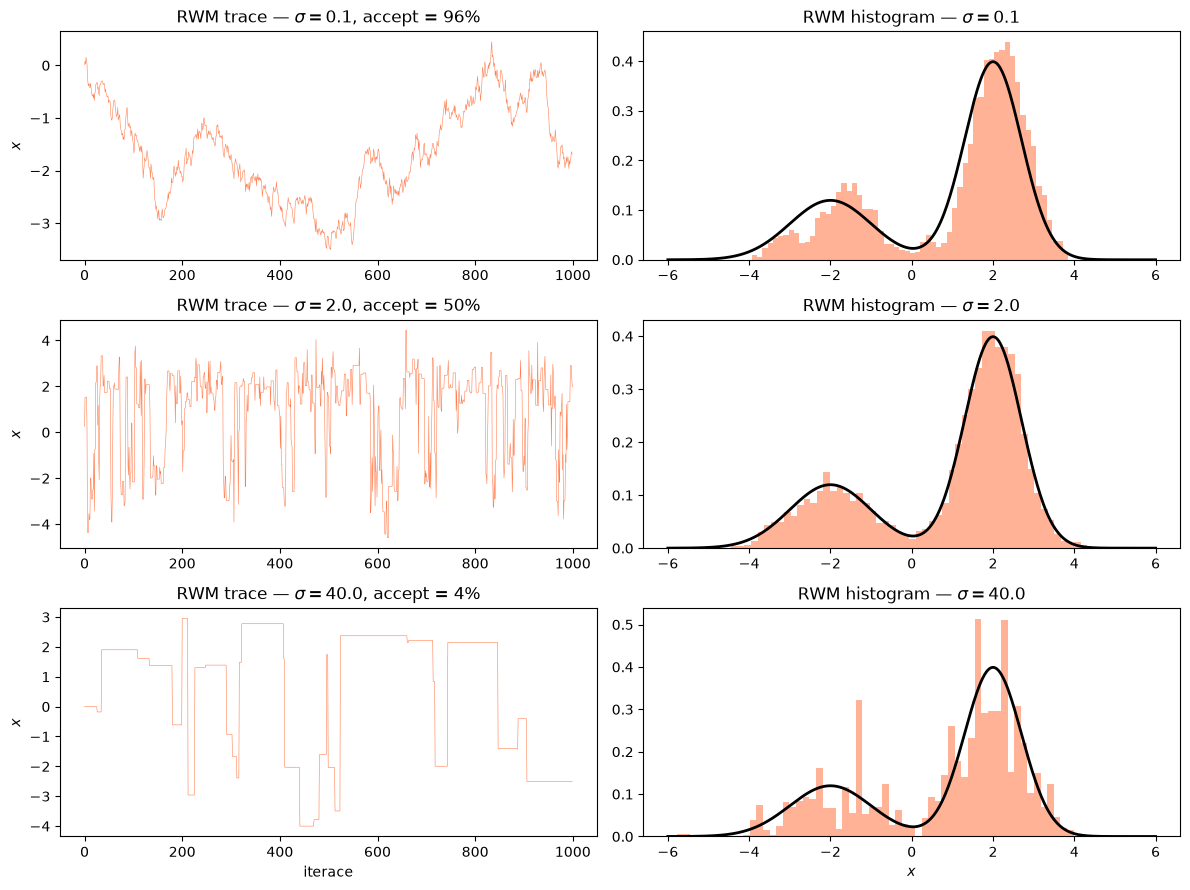

In [3]:
N = 10_000  # počet vzorků

# --- RWM se třemi různými hodnotami σ ---
sigmas = [0.1, 2.0, 40.0]
fig, axes = plt.subplots(len(sigmas), 2, figsize=(12, 3 * len(sigmas)))

for i, sigma in enumerate(sigmas):
    start_time = time.time()
    samples_mh, acc, n_evals_mh = metropolis_hastings(log_target_pdf, x0=0.0, n_samples=N, proposal_std=sigma,
                                                       rng=np.random.default_rng(0))
    elapsed = time.time() - start_time
    print(f"σ = {sigma:5.1f} | accept = {acc:.0%} | vyhodnocení f(x): {n_evals_mh:,} | čas: {elapsed:.3f} s")

    # Trace plot
    axes[i, 0].plot(samples_mh[:1000], lw=0.4, color='coral')
    axes[i, 0].set_ylabel("$x$")
    axes[i, 0].set_title(f"RWM trace — $\\sigma={sigma}$, accept = {acc:.0%}")

    # Histogram (bez burn-in)
    axes[i, 1].hist(samples_mh[1000:], bins=60, density=True, alpha=0.6, color='coral')
    axes[i, 1].plot(x_grid, target_pdf(x_grid), 'k-', lw=2)
    axes[i, 1].set_title(f"RWM histogram — $\\sigma={sigma}$")

axes[-1, 0].set_xlabel("iterace"); axes[-1, 1].set_xlabel("$x$")
plt.tight_layout(); plt.show()

## Slice Sampling (alternativa)

Slice sampling nabízí jiný přístup: místo navrhování bodů a jejich přijímání/zamítání **přímo vzorkuje z oblasti pod grafem** hustoty.

Každý krok je rozdělený na 2 části:
1. **Vertikální:** Vybereme $y \sim \text{Uniform}(0, f(x))$ — náhodnou výšku pod křivkou.
2. **Horizontální:** Najdeme *řez* $S = \{x' : f(x') > y\}$ a vybereme $x'$ rovnoměrně z $S$.

Klíčový rozdíl: nepočítá se žádná pravděpodobnost přijetí a žádný krok se nezamítá (vzorky jsou však stále závislé — jde o Markovův řetězec). Sampler se automaticky přizpůsobuje tvaru rozdělení — když je hustota úzká/široká, řez $S$ je automaticky úzký/široký, takže velikost kroku odpovídá lokálnímu tvaru bez nutnosti ručního ladění.

**Poznámka k řezu $S$:** Řez $S$ je definován jako *celá* množina bodů, kde $f(x') > y$. U multimodálního rozdělení může $S$ sestávat z několika disjunktních intervalů. V *ideálním* případě vzorkujeme ze všech těchto intervalů. V praxi (stepping-out varianta) ale hledáme hranice řezu rozšiřováním okna z aktuálního bodu, takže odlehlé intervaly mohou zůstat mimo nalezené okno. To může mírně zpomalit přechody mezi vzdálenými módy, ale **nenarušuje korektnost** algoritmu — stále vzorkujeme z podmnožiny $S$ a detailní rovnováha je zachována.

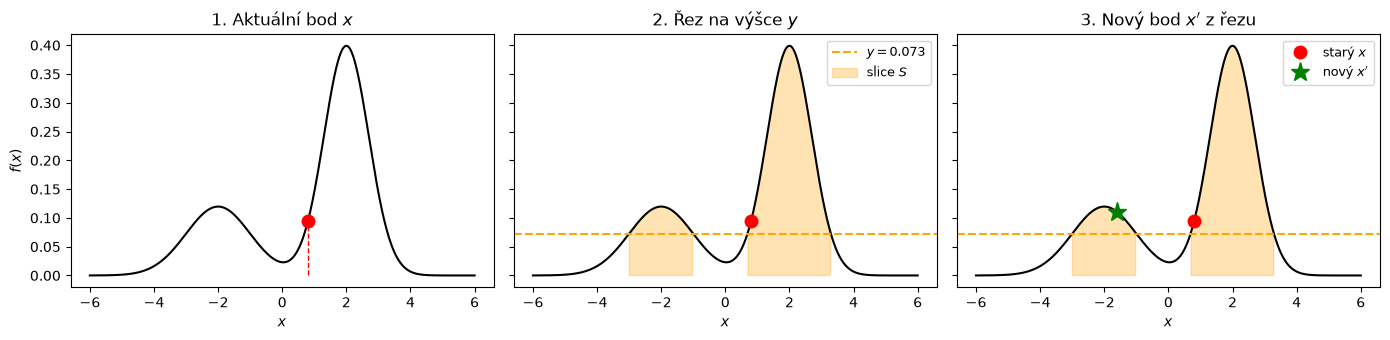

In [4]:
# --- Ilustrace jednoho kroku slice samplingu ---
rng = np.random.default_rng(42)
x_curr = 0.8
f_curr = target_pdf(x_curr)
y_slice = rng.uniform(0, f_curr)

fig, axes = plt.subplots(1, 3, figsize=(14, 3.5), sharex=True, sharey=True)
for ax in axes:
    ax.plot(x_grid, target_pdf(x_grid), 'k-', lw=1.5)
    ax.set_xlabel("$x$")

# 1) Aktuální bod
axes[0].plot(x_curr, f_curr, 'ro', ms=9, zorder=5)
axes[0].vlines(x_curr, 0, f_curr, colors='r', ls='--', lw=1)
axes[0].set_title("1. Aktuální bod $x$")
axes[0].set_ylabel("$f(x)$")

# 2) Řez (slice)
axes[1].plot(x_curr, f_curr, 'ro', ms=9, zorder=5)
axes[1].axhline(y_slice, color='orange', ls='--', lw=1.5, label=f"$y = {y_slice:.3f}$")
axes[1].fill_between(x_grid, 0, target_pdf(x_grid),
                     where=target_pdf(x_grid) > y_slice,
                     alpha=0.3, color='orange', label="slice $S$")
axes[1].legend(fontsize=9)
axes[1].set_title("2. Řez na výšce $y$")

# 3) Nový bod
x_new = -1.6
axes[2].axhline(y_slice, color='orange', ls='--', lw=1.5)
axes[2].fill_between(x_grid, 0, target_pdf(x_grid),
                     where=target_pdf(x_grid) > y_slice,
                     alpha=0.3, color='orange')
axes[2].plot(x_curr, f_curr, 'ro', ms=9, zorder=5, label="starý $x$")
axes[2].plot(x_new, target_pdf(x_new), 'g*', ms=14, zorder=5, label="nový $x'$")
axes[2].legend(fontsize=9)
axes[2].set_title("3. Nový bod $x'$ z řezu")

plt.tight_layout(); plt.show()

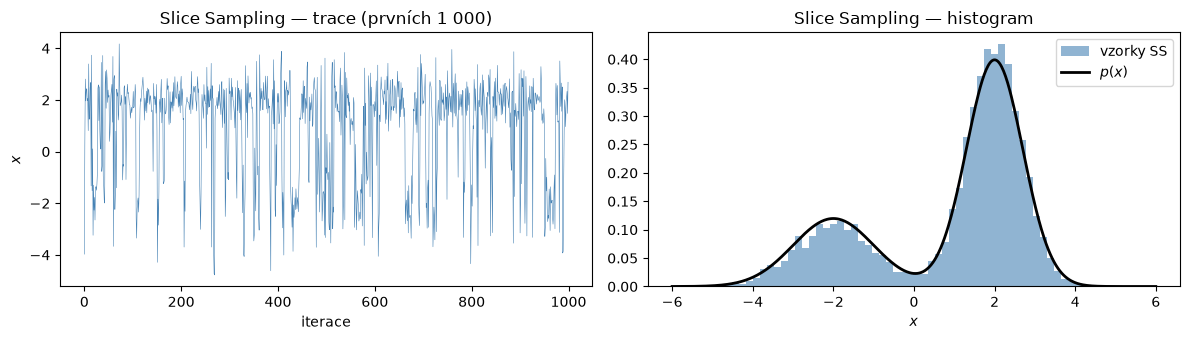

In [5]:
# --- Slice Sampling: trace, histogram ---
samples_ss, n_evals_ss = slice_sampling(log_target_pdf, x0=0.0, n_samples=N, w=2.0, rng=np.random.default_rng(0))

fig, axes = plt.subplots(1, 2, figsize=(12, 3.5))

axes[0].plot(samples_ss[:1000], lw=0.4, color='steelblue')
axes[0].set_title("Slice Sampling — trace (prvních 1 000)")
axes[0].set_xlabel("iterace"); axes[0].set_ylabel("$x$")

axes[1].hist(samples_ss[1000:], bins=60, density=True, alpha=0.6, color='steelblue', label="vzorky SS")
axes[1].plot(x_grid, target_pdf(x_grid), 'k-', lw=2, label="$p(x)$")
axes[1].set_title("Slice Sampling — histogram")
axes[1].legend(); axes[1].set_xlabel("$x$")

plt.tight_layout(); plt.show()

### Volba šířky okna $w$

Slice sampling sice nemá akceptační krok, ale má parametr **$w$** (šířka okna pro stepping-out).
- **Příliš malé $w$**: stepping-out potřebuje mnoho kroků k nalezení hranic řezu → zbytečně mnoho vyhodnocení $f(x)$. Nalezený interval navíc typicky obsahuje jen souvislou část řezu kolem aktuálního bodu, takže přechody mezi vzdálenými módy jsou vzácnější.
- **Příliš velké $w$**: okno přesahuje řez a shrinking ho musí postupně zúžit → několik vyhodnocení $f(x)$ navíc. Interval ale často pokryje oba módy, takže řetězec mezi nimi přechází snadno.

Pro **každé** $w$ generuje řetězec vzorky ze správného rozdělení — stacionární rozdělení na $w$ nezávisí. Volba $w$ ovlivňuje **cenu** jednoho kroku (počet vyhodnocení $f$) a **míchání** řetězce (autokorelaci, četnost přechodů mezi módy). Totéž ovšem platí i pro RWM a $\sigma$: ani špatné $\sigma$ nekazí asymptotickou správnost, jen zhoršuje míchání. Rozdíl je v tom, **jak široký je rozsah parametru, ve kterém sampler funguje rozumně** — u slice samplingu je výrazně širší, jak uvidíme níže.

**Burn-in:** Slice sampling, stejně jako RWM, má burn-in periodu — počáteční vzorky jsou ovlivněny volbou startovního bodu $x_0$, a proto je zahazujeme. Burn-in u slice samplingu bývá typicky kratší, protože řetězec se pohybuje efektivněji (nejsou zamítané kroky).


w =   0.1 | vyhodnocení f(x): 360,774 | čas: 0.372 s
w =   2.0 | vyhodnocení f(x): 65,553 | čas: 0.098 s


w =  40.0 | vyhodnocení f(x): 77,532 | čas: 0.155 s


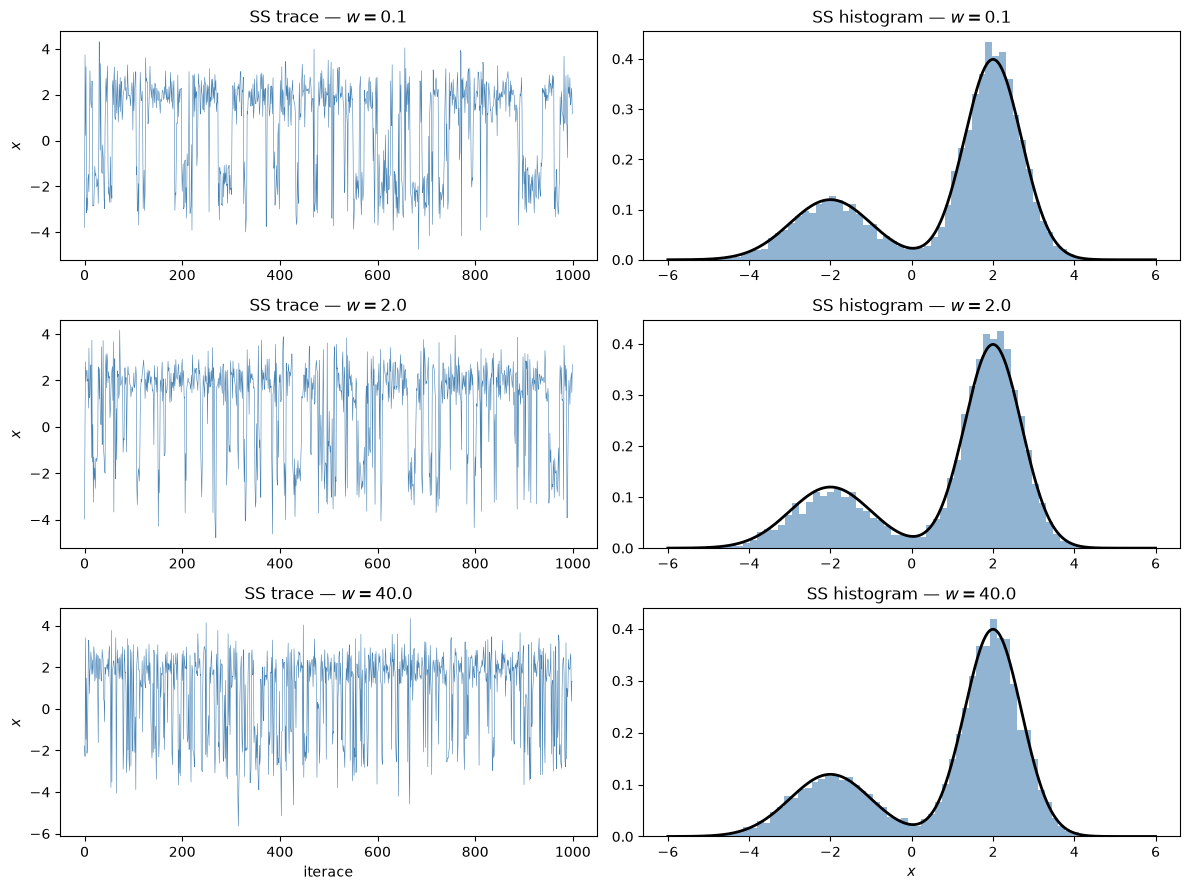

In [6]:
# --- Slice Sampling s různými w ---
ws = [0.1, 2.0, 40.0]
fig, axes = plt.subplots(len(ws), 2, figsize=(12, 3 * len(ws)))

for i, w in enumerate(ws):
    start_time = time.time()
    samples_w, n_evals_w = slice_sampling(log_target_pdf, x0=0.0, n_samples=N, w=w, rng=np.random.default_rng(0))
    elapsed = time.time() - start_time
    print(f"w = {w:5.1f} | vyhodnocení f(x): {n_evals_w:,} | čas: {elapsed:.3f} s")

    axes[i, 0].plot(samples_w[:1000], lw=0.4, color='steelblue')
    axes[i, 0].set_ylabel("$x$")
    axes[i, 0].set_title(f"SS trace — $w={w}$")

    axes[i, 1].hist(samples_w[1000:], bins=60, density=True, alpha=0.6, color='steelblue')
    axes[i, 1].plot(x_grid, target_pdf(x_grid), 'k-', lw=2)
    axes[i, 1].set_title(f"SS histogram — $w={w}$")

axes[-1, 0].set_xlabel("iterace"); axes[-1, 1].set_xlabel("$x$")
plt.tight_layout(); plt.show()

### Férové srovnání: efektivní počet vzorků na jedno vyhodnocení $f$

Počet vzorků řetězce není dobrá míra kvality — vzorky MCMC jsou autokorelované. Standardní mírou je **efektivní počet vzorků** $\mathrm{ESS} = n/\tau$, kde $\tau = 1 + 2\sum_{k\ge 1}\rho_k$ je *integrovaný autokorelační čas* a $\rho_k$ autokorelace se zpožděním $k$. ESS říká, kolika nezávislým vzorkům řetězec délky $n$ odpovídá.

Protože v bayesovské inverzi je drahé každé vyhodnocení $f$ (= běh modelu), je rozumnou srovnávací metrikou **ESS na jedno vyhodnocení $f$**. Časy běhu v sekundách jsou naopak zavádějící — závisí na implementaci hustoty, ne na algoritmu. Jako doplňkovou diagnostiku míchání u bimodálního rozdělení počítáme i počet přechodů mezi módy (změn znaménka $x$).


In [7]:
# --- IACT, ESS a počet přechodů mezi módy pro různé σ a w ---
def iact(x, max_lag=2000):
    """Integrovaný autokorelační čas (Geyerova metoda 'initial positive sequence')."""
    x = np.asarray(x) - np.mean(x)
    n = len(x)
    f = np.fft.rfft(x, 2 * n)
    acf = np.fft.irfft(f * np.conj(f))[:max_lag] / (np.var(x) * n)
    tau = -1.0
    for k in range(0, max_lag - 1, 2):
        pair = acf[k] + acf[k + 1]
        if pair <= 0:
            break
        tau += 2 * pair
    return tau

burn_in = 1000
rows = []
for sigma in sigmas:
    s, acc, ne = metropolis_hastings(log_target_pdf, x0=0.0, n_samples=N, proposal_std=sigma,
                                     rng=np.random.default_rng(0))
    rows.append(("RWM", f"σ = {sigma}", s[burn_in:], ne))
for w in ws:
    s, ne = slice_sampling(log_target_pdf, x0=0.0, n_samples=N, w=w, rng=np.random.default_rng(0))
    rows.append(("slice", f"w = {w}", s[burn_in:], ne))

print(f"{'metoda':6} {'parametr':9} | {'IACT':>6} | {'přechodů mezi módy':>18} | {'vyhodnocení f / vzorek':>22} | {'ESS / 1000 vyhodnocení':>22}")
print("-" * 92)
for name, par, s, ne in rows:
    tau = iact(s)
    evals_per_sample = ne / N
    switches = int(np.sum(np.diff(s < 0) != 0))
    ess_per_1000_evals = 1000 * (len(s) / tau) / (evals_per_sample * len(s))
    print(f"{name:6} {par:9} | {tau:6.1f} | {switches:18d} | {evals_per_sample:22.1f} | {ess_per_1000_evals:22.1f}")


metoda parametr  |   IACT | přechodů mezi módy | vyhodnocení f / vzorek | ESS / 1000 vyhodnocení
--------------------------------------------------------------------------------------------
RWM    σ = 0.1   | 1985.1 |                 11 |                    1.0 |                    0.5
RWM    σ = 2.0   |   11.8 |                712 |                    1.0 |                   84.8
RWM    σ = 40.0  |   44.5 |                161 |                    1.0 |                   22.5
slice  w = 0.1   |    7.9 |                770 |                   36.1 |                    3.5
slice  w = 2.0   |    4.6 |               1300 |                    6.6 |                   33.4
slice  w = 40.0  |    2.5 |               2253 |                    7.8 |                   51.8


## Shrnutí

| Vlastnost | Random Walk Metropolis (RWM) | Slice Sampling |
|---|---|---|
| Akceptační krok | Ano (když je návrh zamítnut, řetězec stojí) | Ne (bez zamítání; vzorky jsou však stále autokorelované) |
| Klíčový parametr | $\sigma$ (šířka návrhu) — **velmi citlivý** | $w$ (šířka okna) — **málo citlivý** |
| Stacionární rozdělení | Správné pro každé $\sigma$ | Správné pro každé $w$ |
| Špatná volba parametru | Řetězec se téměř nehýbe, nebo téměř vše zamítá — míchání se zhorší o řády | Roste počet vyhodnocení $f$, míchání se zhorší jen mírně |
| Počet vyhodnocení $f(x)$ v každém kroku | 1 (ale mnohé návrhy zamítnuty) | Více (stepping-out + shrinking) |
| Férová metrika | ESS na jedno vyhodnocení $f$ | ESS na jedno vyhodnocení $f$ |
| Robustnost | Nižší — vyžaduje pečlivé ladění | Vyšší — přizpůsobuje se tvaru rozdělení |

Na tomto jednoduchém 1D příkladu **dobře naladěný RWM** ($\sigma \approx 2$) dosahuje vyššího ESS na jedno vyhodnocení $f$ než slice sampling — cenou za „bezúdržbovost“ slice samplingu je několik vyhodnocení $f$ na krok. Slice sampling ale dává použitelný řetězec pro **všechny** testované hodnoty $w$ (přes tři řády), zatímco RWM pro dvě ze tří hodnot $\sigma$ prakticky nefunguje.

**Závěr:** Slice sampling může být zajímavou alternativou k RWM zejména tam, kde je ladění návrhového rozdělení obtížné nebo drahé, např. u složitějších aposteriorních rozdělení v bayesovské inverzi. Zda a kdy jeho robustnost převáží vyšší cenu jednoho kroku — zvlášť ve více dimenzích a u skutečných inverzních úloh — je otázka, kterou má tato práce systematicky prozkoumat.
